# Taller 3 — APIs Públicas, MongoDB y EDA
**Bases de Datos para Ciencia de Datos** · Docente: Miguel Ramos García

**API utilizada:** [Open Brewery DB](https://openbrewerydb.org) (cervecerías del mundo).

**Flujo:** API → `ingesta.py` → MongoDB Atlas (`taller3_db.raw_data`) → este notebook (selección de variables, EDA y visualización).

## 0. Importación de librerías y configuración
Se importan las librerías para cargar la configuración (`dotenv`), conectarse a MongoDB (`pymongo`), manipular datos (`pandas`) y graficar (`matplotlib`, `seaborn`). La dirección de conexión a Atlas se lee desde el archivo `.env`, para no exponer la contraseña en el notebook.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv()

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

MONGO_URI = os.getenv("MONGO_URI", "mongodb://localhost:27017")
DB_NAME = "taller3_db"
COLLECTION_NAME = "raw_data"

## 1. Selección de variables
### 1.1 Lectura de la colección desde MongoDB
Se abre la conexión con Atlas y se confirma que la colección `raw_data` contiene al menos 100 documentos, que es el requisito del taller.

In [2]:
client = MongoClient(MONGO_URI, serverSelectionTimeoutMS=8000)
collection = client[DB_NAME][COLLECTION_NAME]

total_docs = collection.count_documents({})
print(f"Documentos en {DB_NAME}.{COLLECTION_NAME}: {total_docs}")
assert total_docs >= 100, "La colección debe tener al menos 100 documentos"

Documentos en taller3_db.raw_data: 400


### 1.2 Creación del DataFrame con 10 variables relevantes
Se leen los documentos crudos y se conservan **únicamente 10 columnas**: `name`, `brewery_type`, `city`, `state_province`, `country`, `latitude`, `longitude`, `website_url`, `phone` y `postal_code`. Se usa una proyección en MongoDB para traer solo esos campos, y el `_id` (el ID de la API) queda como índice.

In [3]:
columnas = ["name", "brewery_type", "city", "state_province", "country",
            "latitude", "longitude", "website_url", "phone", "postal_code"]

proyeccion = {c: 1 for c in columnas}
documentos = list(collection.find({}, proyeccion))

df = pd.DataFrame(documentos).set_index("_id")
df = df.reindex(columns=columnas)
print(f"DataFrame: {df.shape[0]} filas x {df.shape[1]} columnas")

DataFrame: 400 filas x 10 columnas


### 1.3 Limpieza básica
- Se eliminan los espacios sobrantes en las columnas de texto y las cadenas vacías se convierten en valores nulos.
- `latitude` y `longitude` se convierten a tipo numérico.
- Se eliminan los registros duplicados, si los hubiera.

In [4]:
texto = ["name", "brewery_type", "city", "state_province", "country",
         "website_url", "phone", "postal_code"]
for c in texto:
    df[c] = df[c].astype("string").str.strip().replace("", pd.NA)

df["latitude"] = pd.to_numeric(df["latitude"], errors="coerce")
df["longitude"] = pd.to_numeric(df["longitude"], errors="coerce")

antes = len(df)
df = df[~df.index.duplicated(keep="first")].drop_duplicates()
print(f"Filas antes: {antes} | después de eliminar duplicados: {len(df)}")

Filas antes: 400 | después de eliminar duplicados: 400


## 2. Análisis Exploratorio de Datos (EDA)
### A. Inspección básica
#### A.1 Primeras filas: `head()`
Se muestran las primeras 5 filas del DataFrame limpio para revisar a simple vista cómo quedaron las 10 variables.

In [5]:
df.head()

,name,brewery_type,city,state_province,country,latitude,longitude,website_url,phone,postal_code
_id,,,,,,,,,,
ae7b3174-8be8-4d53-a3a5-9b8240970eea,'s,brewpub,Kronach,Bayern,Germany,50.241246,11.327765,http://www.antla.de,+49 9261 628000,96317
aa7cbe9b-3a0f-4888-9884-6186b0042b55,’t Drankorgel,micro,Mol,Vlaanderen,Belgium,51.176258,5.056955,http://tdrankorgel.be/,+32 496 76 40 63,2400
1034754f-abf9-4b42-bd6d-37e110ba4b1a,'T Kroontje,micro,Lebbeke,Vlaanderen,Belgium,51.007888,4.091393,http://www.tkroontje.be/,+32 495 43 33 25,9280
907826b3-6902-4d28-a5e2-f73084bebeed,'t Veense Brouwhuys,micro,Roelofarendsveen,Zuid-Holland,Netherlands,NaN,NaN,https://www.t-veen.nl/t-veense-brouwhuys/,071-3314585,2371 EG
5128df48-79fc-4f0f-8b52-d06be54d0cec,(405) Brewing Co,micro,Norman,Oklahoma,United States,35.257389,-97.468182,http://www.405brewing.com,4058160490,73069-8224


#### A.2 Tipos de datos: `info()`
Se revisa el tipo de dato de cada columna y cuántos valores no nulos tiene. Las columnas de texto deben aparecer como `string` y `latitude` y `longitude` como `float64`.

In [6]:
df.info()

<class 'pandas.DataFrame'>
Index: 400 entries, ae7b3174-8be8-4d53-a3a5-9b8240970eea to 3345a490-cc70-449e-b037-939398bd0f25
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   name            400 non-null    string 
 1   brewery_type    400 non-null    string 
 2   city            400 non-null    string 
 3   state_province  400 non-null    string 
 4   country         400 non-null    string 
 5   latitude        314 non-null    float64
 6   longitude       314 non-null    float64
 7   website_url     351 non-null    string 
 8   phone           355 non-null    string 
 9   postal_code     399 non-null    string 
dtypes: float64(2), string(8)
memory usage: 50.5+ KB


#### A.3 Verificación de valores nulos
Se cuenta cuántos valores faltan en cada columna y qué porcentaje del total representan.

In [7]:
nulos = pd.DataFrame({
    "nulos": df.isna().sum(),
    "porcentaje_%": (df.isna().mean() * 100).round(2)
})
nulos

,nulos,porcentaje_%
name,0,0.00
brewery_type,0,0.00
city,0,0.00
state_province,0,0.00
country,0,0.00
latitude,86,21.50
longitude,86,21.50
website_url,49,12.25
phone,45,11.25
postal_code,1,0.25


### B. Insights numéricos (5 datos relevantes)
Se calculan cinco datos estadísticos y conteos sobre las cervecerías, cada uno en su propia celda.

**Insight 1: tipo de cervecería más frecuente y su proporción.**

In [8]:
conteo_tipos = df["brewery_type"].value_counts()
tipo_top = conteo_tipos.idxmax()
pct_tipo_top = conteo_tipos.max() / len(df) * 100
print(f"Insight 1: El tipo de cervecería más común es '{tipo_top}' con {conteo_tipos.max()} "
      f"establecimientos ({pct_tipo_top:.1f}% del total).")

Insight 1: El tipo de cervecería más común es 'micro' con 213 establecimientos (53.2% del total).


In [9]:
conteo_estados = df["state_province"].value_counts()
print(f"Insight 2: El estado/provincia con más cervecerías es '{conteo_estados.idxmax()}' "
      f"con {conteo_estados.max()} establecimientos.")

Insight 2: El estado/provincia con más cervecerías es 'California' con 39 establecimientos.


In [10]:
conteo_ciudades = df["city"].value_counts()
print(f"Insight 3: La ciudad con más cervecerías es '{conteo_ciudades.idxmax()}' "
      f"con {conteo_ciudades.max()} establecimientos.")

Insight 3: La ciudad con más cervecerías es 'San Diego' con 8 establecimientos.


**Insight 3: ciudad con más cervecerías.**

**Insight 2: estado o provincia con más cervecerías.**

**Insight 4: porcentaje de cervecerías con sitio web.**

In [11]:
con_web = df["website_url"].notna().sum()
print(f"Insight 4: {con_web} de {len(df)} cervecerías tienen sitio web "
      f"({con_web / len(df) * 100:.1f}%); {len(df) - con_web} no lo tienen.")

Insight 4: 351 de 400 cervecerías tienen sitio web (87.8%); 49 no lo tienen.


**Insight 5: países representados y país dominante.**

In [12]:
conteo_paises = df["country"].value_counts()
print(f"Insight 5: Hay {df['country'].nunique()} país(es) en la muestra; el dominante es "
      f"'{conteo_paises.idxmax()}' con {conteo_paises.max()} registros "
      f"({conteo_paises.max() / len(df) * 100:.1f}%).")

Insight 5: Hay 15 país(es) en la muestra; el dominante es 'United States' con 302 registros (75.5%).


### C. Visualización (3 gráficos)
#### C.1 Gráfico de torta: proporción de cervecerías por tipo
Los tipos que representan menos del 2% se agrupan en la categoría *other* para que la torta sea legible.

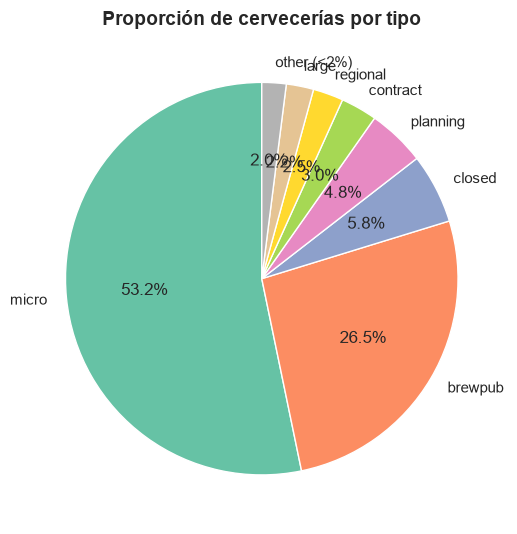

In [13]:
prop = df["brewery_type"].value_counts(normalize=True)
principales = prop[prop >= 0.02]
otros = prop[prop < 0.02].sum()
if otros > 0:
    principales["other (<2%)"] = otros

fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.pie(principales, labels=principales.index, autopct="%1.1f%%", startangle=90,
       colors=sns.color_palette("Set2", len(principales)),
       wedgeprops={"edgecolor": "white"})
ax.set_title("Proporción de cervecerías por tipo", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

#### C.2 Gráfico de barras: Top 10 de estados o provincias con más cervecerías
Se muestran los 10 estados o provincias con mayor número de cervecerías, con el conteo escrito al final de cada barra.

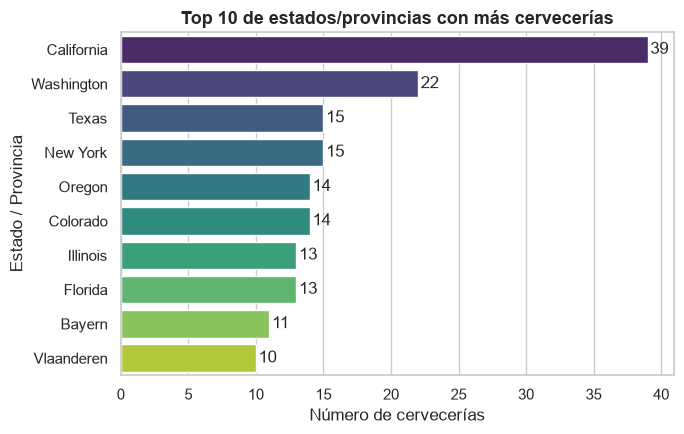

In [14]:
top_estados = df["state_province"].value_counts().head(10)

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=top_estados.values, y=top_estados.index, hue=top_estados.index,
            palette="viridis", legend=False, ax=ax)
ax.set_title("Top 10 de estados/provincias con más cervecerías", fontsize=13, fontweight="bold")
ax.set_xlabel("Número de cervecerías")
ax.set_ylabel("Estado / Provincia")
for i, v in enumerate(top_estados.values):
    ax.text(v + 0.2, i, str(v), va="center")
plt.tight_layout()
plt.show()

#### C.3 Histograma: distribución de la latitud de las cervecerías
Se muestra cómo se distribuyen las cervecerías según su latitud. Solo se usan los registros que tienen coordenadas, y la línea roja marca la latitud promedio.

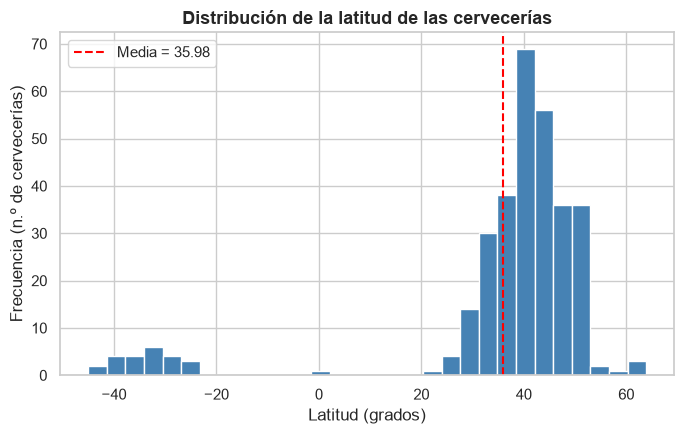

In [15]:
lat = df["latitude"].dropna()

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.hist(lat, bins=30, color="steelblue", edgecolor="white")
ax.axvline(lat.mean(), color="red", linestyle="--", label=f"Media = {lat.mean():.2f}")
ax.set_title("Distribución de la latitud de las cervecerías", fontsize=13, fontweight="bold")
ax.set_xlabel("Latitud (grados)")
ax.set_ylabel("Frecuencia (n.º de cervecerías)")
ax.legend()
plt.tight_layout()
plt.show()

## 3. Conclusiones
A partir de las 400 cervecerías de Open Brewery DB almacenadas en MongoDB Atlas se obtuvo lo siguiente:

1. El tipo de cervecería más común es micro, con 213 establecimientos (53.2% del total).
2. El estado o provincia con más cervecerías es California, con 39 establecimientos.
3. La ciudad con más cervecerías es San Diego, con 8 establecimientos.
4. 351 de 400 cervecerías (87.8%) tienen sitio web.
5. La muestra incluye 15 países, y el dominante es **Estados Unidos** con 75.5% de los registros.

En la revisión de nulos, `latitude` y `longitude` fueron las columnas con más datos faltantes (86 registros, 21.5%), por lo que el histograma se construyó con 314 registros.

In [16]:
client.close()